# 02 · Advanced Statistical Analysis & Hypothesis Testing

Executes the analysis plan sections **A–E** of the preregistration (`prereg-v1`) on the real series.

**Estimand caveat (preregistered).** Every event day is a Friday or Saturday; every holiday is a Sunday. Event-vs-regular differences therefore bundle any marketing effect with day-of-week effects. Results are associations, not causal marketing lift.

In [1]:
import sys, warnings, pathlib, subprocess, hashlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown, Image
from rq.config import *
from rq.data import load_raw, add_calendar
from rq import stats_tests as st
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
PAL = {"Event": "#d95f02", "Holiday": "#7570b3", "Regular": "#1b9e77"}
df = add_calendar(load_raw(RAW))
print(f"rows={len(df)}  window={df.date.min().date()} .. {df.date.max().date()}  seed={SEED}")

rows=30  window=2026-06-01 .. 2026-06-30  seed=20260601


## Hypotheses (as preregistered)

| Test | H0 | HA |
|---|---|---|
| **Primary** Event vs Regular (Welch t / Mann-Whitney U) | μ_event = μ_regular | μ_event ≠ μ_regular (expected direction: >) |
| One-way ANOVA (Event, Holiday, Regular) | all three means equal | at least one mean differs |
| Tukey HSD | pairwise means equal | pairwise means differ |
| Two-way ANOVA (week × day type) | no week effect / no day-type effect / no interaction | effect present |

α = 0.05 (two-sided); 95% confidence intervals. Decision rule: Welch is primary iff Shapiro-Wilk p ≥ .05 in both compared groups, otherwise Mann-Whitney U. Both always reported.

## 1. Descriptive statistics and distributions

,n,mean,sd,median,min,max
day_type,,,,,,
Event,8,156.62,11.71,157.0,137,174
Holiday,4,149.75,6.65,149.0,143,158
Regular,18,133.94,8.89,134.5,118,147


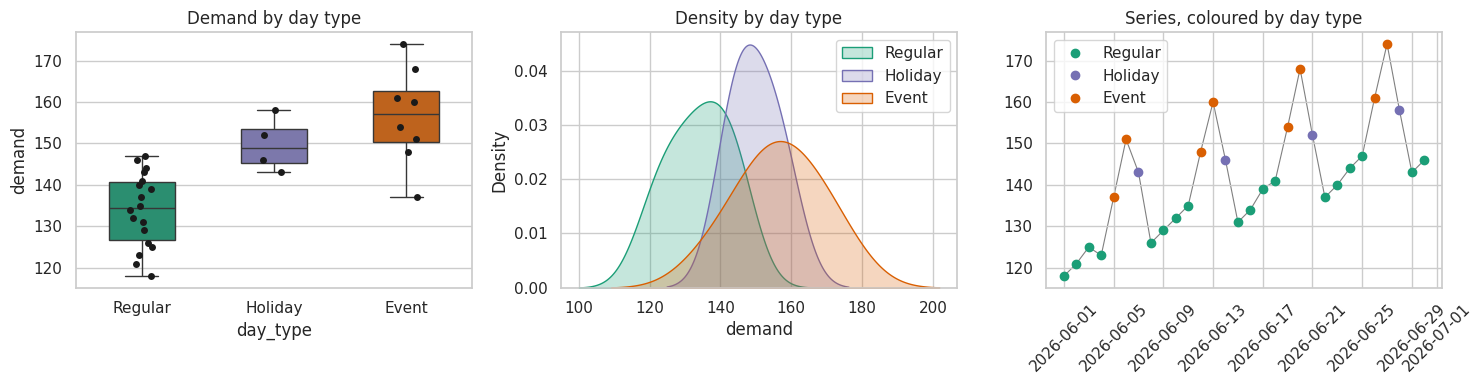

In [2]:
desc = df.groupby("day_type").demand.agg(n="count", mean="mean", sd="std", median="median", min="min", max="max").loc[["Event","Holiday","Regular"]]
display(desc.round(2))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
order = ["Regular", "Holiday", "Event"]
sns.boxplot(data=df, x="day_type", y="demand", order=order, palette=PAL, ax=ax[0], width=.5)
sns.stripplot(data=df, x="day_type", y="demand", order=order, color="k", size=5, ax=ax[0])
ax[0].set_title("Demand by day type")
for k in order: sns.kdeplot(df.loc[df.day_type == k, "demand"], ax=ax[1], label=k, color=PAL[k], fill=True, alpha=.25, bw_adjust=1.2)
ax[1].legend(); ax[1].set_title("Density by day type")
for k in order: ax[2].plot(df.loc[df.day_type == k, "date"], df.loc[df.day_type == k, "demand"], "o", color=PAL[k], label=k)
ax[2].plot(df.date, df.demand, color="grey", lw=.8, zorder=0); ax[2].tick_params(axis="x", rotation=45); ax[2].set_title("Series, coloured by day type"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIGS / "02_distributions.png", dpi=150); plt.show()
desc.round(3).to_csv(TABLES / "02_descriptives.csv")

## 2. Normality: Shapiro-Wilk and Kolmogorov-Smirnov
KS with parameters estimated from the sample is anti-conservative, so the **Lilliefors-corrected** p-value is also shown (and takes precedence if they disagree).

,group,n,mean,sd,shapiro_W,shapiro_p,ks_D,ks_p,lilliefors_D,lilliefors_p,normal_by_shapiro
0,Event,8,156.6250,11.7100,0.9885,0.9924,0.1134,0.9995,0.1134,0.9900,True
1,Holiday,4,149.7500,6.6521,0.9631,0.7982,0.2135,0.9764,0.2135,0.7833,True
2,Regular,18,133.9444,8.8880,0.9619,0.6382,0.1041,0.9782,0.1041,0.8641,True


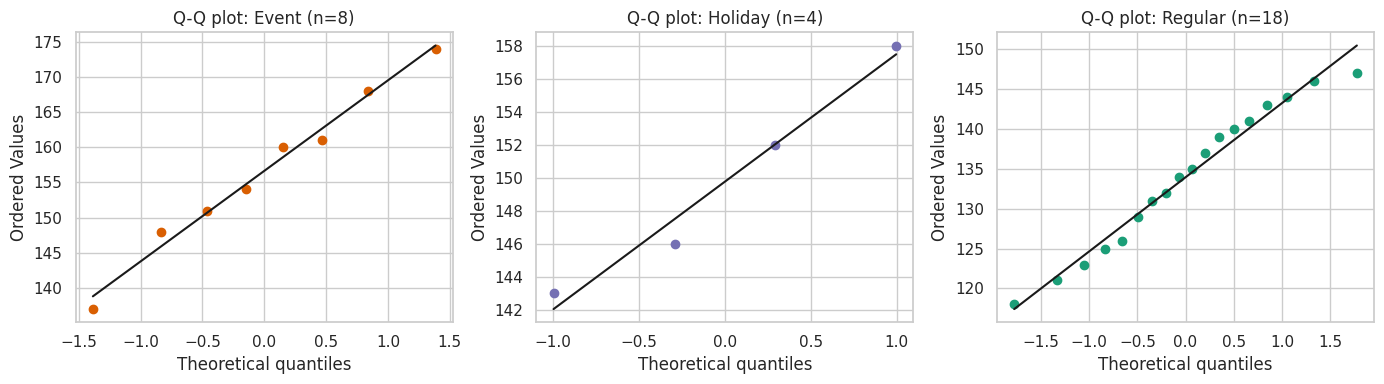

All groups pass Shapiro-Wilk at 0.05: True


In [3]:
groups = {k: df.loc[df.day_type == k, "demand"] for k in ["Event", "Holiday", "Regular"]}
norm = st.normality_table(groups)
display(norm.round(4)); norm.round(4).to_csv(TABLES / "02_normality.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (k, x) in zip(ax, groups.items()):
    stats.probplot(x, dist="norm", plot=a); a.set_title(f"Q-Q plot: {k} (n={len(x)})")
    a.get_lines()[0].set_color(PAL[k]); a.get_lines()[1].set_color("k")
plt.tight_layout(); plt.savefig(FIGS / "02_qq.png", dpi=150); plt.show()
print("All groups pass Shapiro-Wilk at 0.05:", bool(norm.normal_by_shapiro.all()))

## 3. Primary test: two-sample comparison, Event vs Regular
Welch two-sample t-test **and** Mann-Whitney U, with effect sizes and confidence intervals.

,value
n (event / regular),8 / 18
mean (event / regular),156.62 / 133.94
difference in means,22.68
Welch t (df),4.888 (10.75)
Welch p,0.00051
Welch 95% CI of difference,"[12.44, 32.92]"
Hedges g [95% CI],"2.24 [1.21, 3.27]"
Mann-Whitney U / p,136.5 / 0.00038
rank-biserial r,0.90
Hodges-Lehmann shift [95% bootstrap CI],"22.5 [14.0, 31.5]"


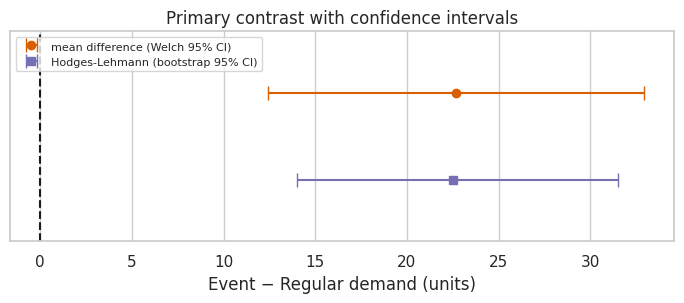

In [4]:
ev, rg = groups["Event"].to_numpy(), groups["Regular"].to_numpy()
P = st.two_sample(ev, rg)
tbl = pd.Series({
 "n (event / regular)": f"{P['n_a']} / {P['n_b']}",
 "mean (event / regular)": f"{P['mean_a']:.2f} / {P['mean_b']:.2f}",
 "difference in means": f"{P['diff']:.2f}",
 "Welch t (df)": f"{P['welch_t']:.3f} ({P['welch_df']:.2f})",
 "Welch p": f"{P['welch_p']:.2g}",
 "Welch 95% CI of difference": f"[{P['welch_ci_low']:.2f}, {P['welch_ci_high']:.2f}]",
 "Hedges g [95% CI]": f"{P['hedges_g']:.2f} [{P['g_ci_low']:.2f}, {P['g_ci_high']:.2f}]",
 "Mann-Whitney U / p": f"{P['mwu_U']:.1f} / {P['mwu_p']:.2g}",
 "rank-biserial r": f"{P['rank_biserial']:.2f}",
 "Hodges-Lehmann shift [95% bootstrap CI]": f"{P['hl_shift']:.1f} [{P['hl_ci_low']:.1f}, {P['hl_ci_high']:.1f}]",
 "permutation p": f"{P['perm_p']:.2g}",
 "primary test (rule A)": P["primary_test"], "primary p": f"{P['primary_p']:.2g}", "reject H0 at 0.05": P["reject_null"]}, name="value")
display(tbl.to_frame()); pd.Series(P).to_csv(TABLES / "02_primary_test.csv")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(P["diff"], 1, xerr=[[P["diff"] - P["welch_ci_low"]], [P["welch_ci_high"] - P["diff"]]], fmt="o", color="#d95f02", capsize=5, label="mean difference (Welch 95% CI)")
ax.errorbar(P["hl_shift"], 0, xerr=[[P["hl_shift"] - P["hl_ci_low"]], [P["hl_ci_high"] - P["hl_shift"]]], fmt="s", color="#7570b3", capsize=5, label="Hodges-Lehmann (bootstrap 95% CI)")
ax.axvline(0, color="k", ls="--"); ax.set_yticks([]); ax.set_xlabel("Event − Regular demand (units)"); ax.set_ylim(-.7, 1.7); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Primary contrast with confidence intervals"); plt.tight_layout(); plt.savefig(FIGS / "02_primary_ci.png", dpi=150); plt.show()

## 4. One-way ANOVA with Tukey HSD (Event, Holiday, Regular)

,F,p,df_between,df_within,eta2,omega2,brown_forsythe_stat,brown_forsythe_p,kruskal_H,kruskal_p,n
one-way ANOVA,17.28888,0.00001,2.0,27.0,0.56153,0.5206,0.81669,0.45251,16.65256,0.00024,30.0


,group1,group2,mean_diff,ci_low,ci_high,p_adj,reject
0,Event,Holiday,6.8750,-7.5456,21.2956,0.4738,False
1,Event,Regular,22.6806,12.6743,32.6869,0.0000,True
2,Holiday,Regular,15.8056,2.7885,28.8226,0.0150,True


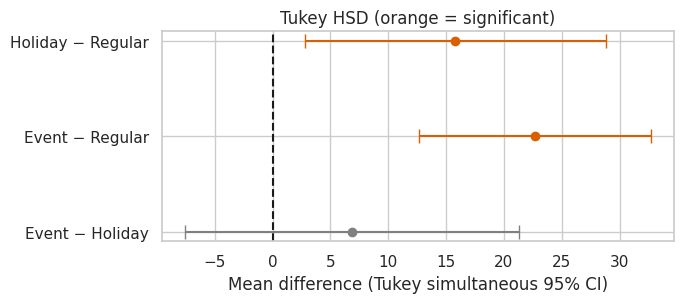

Brown-Forsythe p = 0.453 (variances homogeneous if >= .05); Kruskal-Wallis p = 0.00024


In [5]:
S, tk = st.anova_oneway(df)
display(pd.Series(S, name="one-way ANOVA").to_frame().T.round(5))
display(tk.round(4)); tk.round(4).to_csv(TABLES / "02_tukey.csv", index=False)
pd.Series(S).to_csv(TABLES / "02_oneway.csv")
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, r in tk.iterrows():
    ax.errorbar(r.mean_diff, i, xerr=[[r.mean_diff - r.ci_low], [r.ci_high - r.mean_diff]], fmt="o", capsize=5, color="#d95f02" if r.reject else "grey")
ax.set_yticks(range(len(tk))); ax.set_yticklabels([f"{a} − {b}" for a, b in zip(tk.group1, tk.group2)])
ax.axvline(0, color="k", ls="--"); ax.set_xlabel("Mean difference (Tukey simultaneous 95% CI)"); ax.set_title("Tukey HSD (orange = significant)")
plt.tight_layout(); plt.savefig(FIGS / "02_tukey.png", dpi=150); plt.show()
print(f"Brown-Forsythe p = {S['brown_forsythe_p']:.3f} (variances homogeneous if >= .05); Kruskal-Wallis p = {S['kruskal_p']:.2g}")

## 5. Two-way ANOVA: calendar week × day type
Weeks 1–4 only (complete Mon–Sun weeks, n = 28), Type II sums of squares. The Holiday cell has one observation per week, so the interaction is interpreted cautiously.

,sum_sq,df,F,PR(>F),partial_eta2
C(week),1601.8571,3.0,15.6757,0.0001,0.7461
C(day_type),3357.4821,2.0,49.2841,0.0000,0.8603
C(week):C(day_type),33.5179,6.0,0.1640,0.9828,0.0579
Residual,545.0000,16.0,NaN,NaN,NaN


n = 28


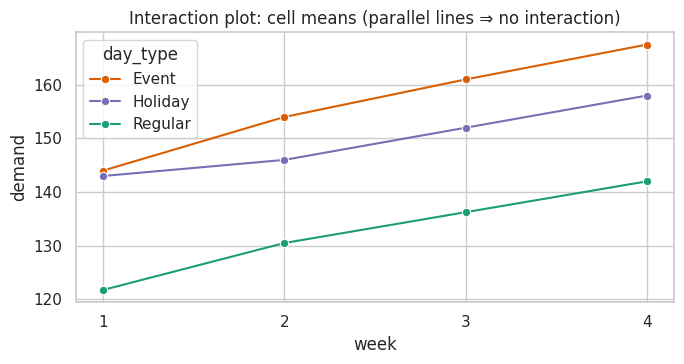

In [6]:
T, n2 = st.anova_twoway(df)
display(T.round(4)); T.round(4).to_csv(TABLES / "02_twoway.csv"); print("n =", n2)
cell = df[df.week <= 4].groupby(["week", "day_type"]).demand.mean().reset_index()
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.lineplot(data=cell, x="week", y="demand", hue="day_type", palette=PAL, marker="o", ax=ax)
ax.set_xticks([1, 2, 3, 4]); ax.set_title("Interaction plot: cell means (parallel lines ⇒ no interaction)")
plt.tight_layout(); plt.savefig(FIGS / "02_interaction.png", dpi=150); plt.show()

## 6. Robustness checks for the primary contrast (preregistered E1–E4)

In [7]:
R, loo = st.robustness(df)
rob = pd.DataFrame({
 "check": ["primary Welch difference", "1 permutation test (p)", "2 OLS + linear trend, HC3 (coef)", "3 leave-one-week-out (range of diff)", "4 log-scale Welch (p; log diff)"],
 "estimate": [f"{P['diff']:.2f}", f"{R['permutation_p']:.2g}", f"{R['ols_trend_coef']:.2f} [{R['ols_trend_ci_low']:.2f}, {R['ols_trend_ci_high']:.2f}], p={R['ols_trend_p']:.1g}",
              f"{loo['diff'].min():.2f} to {loo['diff'].max():.2f} (max p={loo['p'].max():.3g})", f"{R['log_welch_p']:.2g}; {R['log_diff']:.3f} (≈{100*(np.exp(R['log_diff'])-1):.1f}%)"]})
display(rob); display(loo.round(3)); rob.to_csv(TABLES / "02_robustness.csv", index=False)
signs_agree = all([P["diff"] > 0, R["ols_trend_coef"] > 0, R["log_diff"] > 0, (loo["diff"] > 0).all()])
robust = signs_agree and P["welch_ci_low"] > 0 and R["permutation_p"] < .05 and R["log_welch_p"] < .05 and R["ols_trend_p"] < .05
print("Preregistered 'robust' criterion met:", robust)

,check,estimate
0,primary Welch difference,22.68
1,1 permutation test (p),0.0002
2,"2 OLS + linear trend, HC3 (coef)","21.55 [16.11, 27.00], p=8e-15"
3,3 leave-one-week-out (range of diff),21.36 to 24.00 (max p=0.00618)
4,4 log-scale Welch (p; log diff),0.00028; 0.156 (≈16.9%)


,dropped_week,diff,p
0,1,23.405,0.001
1,2,22.571,0.006
2,3,21.881,0.006
3,4,21.357,0.002
4,5,24.000,0.000


Preregistered 'robust' criterion met: True


In [8]:
display(Markdown(f"""## Findings

**Primary result (confirmatory).** Mean demand was **{P['mean_a']:.1f}** on event days (n={P['n_a']}) vs **{P['mean_b']:.1f}** on regular days (n={P['n_b']}): a difference of **{P['diff']:.1f} units** (Welch 95% CI {P['welch_ci_low']:.1f} to {P['welch_ci_high']:.1f}; Hedges g = {P['hedges_g']:.2f}). Normality was not rejected in either group (Shapiro p = {P['shapiro_p_a']:.2f}, {P['shapiro_p_b']:.2f}), so Welch's t-test was the primary test (p = {P['welch_p']:.2g}); Mann-Whitney U agrees (p = {P['mwu_p']:.2g}). **H0 is rejected at α = 0.05.** All four preregistered robustness checks agree in sign and significance (robust: {robust}).

**Secondary (exploratory).** One-way ANOVA across day types: F({S['df_between']},{S['df_within']}) = {S['F']:.1f}, p = {S['p']:.2g}, η² = {S['eta2']:.2f}. Tukey HSD: Event > Regular and Holiday > Regular are significant; Event vs Holiday is not (difference {tk.iloc[0].mean_diff:.1f}, CI {tk.iloc[0].ci_low:.1f} to {tk.iloc[0].ci_high:.1f}). Two-way ANOVA: strong day-type effect and a strong **calendar-week effect** (partial η² = {T.loc['C(week)','partial_eta2']:.2f}, reflecting an upward trend through June), with **no detectable interaction** (p = {T.loc['C(week):C(day_type)','PR(>F)']:.2f}).

**Interpretation limits.** (1) Event days are always Fri/Sat and holidays always Sundays, so these are day-of-week-bundled associations, not a causal marketing lift. (2) n = 30 from a single series; Holiday has n = 4. (3) The upward weekly trend means comparisons across non-overlapping weeks are partly confounded by time; the trend-adjusted OLS estimate ({R['ols_trend_coef']:.1f}) is close to the unadjusted one.
"""))

## Findings

**Primary result (confirmatory).** Mean demand was **156.6** on event days (n=8) vs **133.9** on regular days (n=18): a difference of **22.7 units** (Welch 95% CI 12.4 to 32.9; Hedges g = 2.24). Normality was not rejected in either group (Shapiro p = 0.99, 0.64), so Welch's t-test was the primary test (p = 0.00051); Mann-Whitney U agrees (p = 0.00038). **H0 is rejected at α = 0.05.** All four preregistered robustness checks agree in sign and significance (robust: True).

**Secondary (exploratory).** One-way ANOVA across day types: F(2,27) = 17.3, p = 1.5e-05, η² = 0.56. Tukey HSD: Event > Regular and Holiday > Regular are significant; Event vs Holiday is not (difference 6.9, CI -7.5 to 21.3). Two-way ANOVA: strong day-type effect and a strong **calendar-week effect** (partial η² = 0.75, reflecting an upward trend through June), with **no detectable interaction** (p = 0.98).

**Interpretation limits.** (1) Event days are always Fri/Sat and holidays always Sundays, so these are day-of-week-bundled associations, not a causal marketing lift. (2) n = 30 from a single series; Holiday has n = 4. (3) The upward weekly trend means comparisons across non-overlapping weeks are partly confounded by time; the trend-adjusted OLS estimate (21.6) is close to the unadjusted one.
